In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)


import numpy as np
import tensorflow as tf

import project_images_loader as pil
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.visualization as vis
import utils.util_deep_learning as udl

import discriminator as Discriminator
import generator as Generator
# import feature_extractor as feature_extractor

tf.keras.backend.set_image_data_format("channels_first")


pil.SERVER = True

2024-05-02 01:34:08.912285: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-05-02 01:34:10.123941: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


SERVER: True


In [2]:
input_shape = (192,224,192)

G = Generator.create_generator_model(input_shape)

checkpoint_dir = f"{current_path}/models/training_checkpoints/"
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(G=G)
# checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))



2024-05-02 01:34:13.183968: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1928] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 31141 MB memory:  -> device: 0, name: Tesla V100-PCIE-32GB, pci bus id: 0000:89:00.0, compute capability: 7.0


In [3]:
def save_image(id, img_gen, img_path_name):
    _, affine = pil.load_preprocessed_image(3, id, absolute=True)
    pil.save_image(img_gen.astype(np.float32), affine, img_path_name)

def generate_image(id, G):   
    img_hunt3, _ = pil.load_preprocessed_image(3, id, absolute=True)
    img_hunt4, _ = pil.load_preprocessed_image(4, id, absolute=True)

    img_gen = G(udl.prepare_img_for_gan(img_hunt3, axis_channels=1), training=False)
    img_gen = udl.recover_img_from_gan(img_gen, axis_channels=1)
    return img_hunt3, img_hunt4, img_gen


-------- Checkpoint: 1
ID: 08202


2024-05-02 01:34:14.369552: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


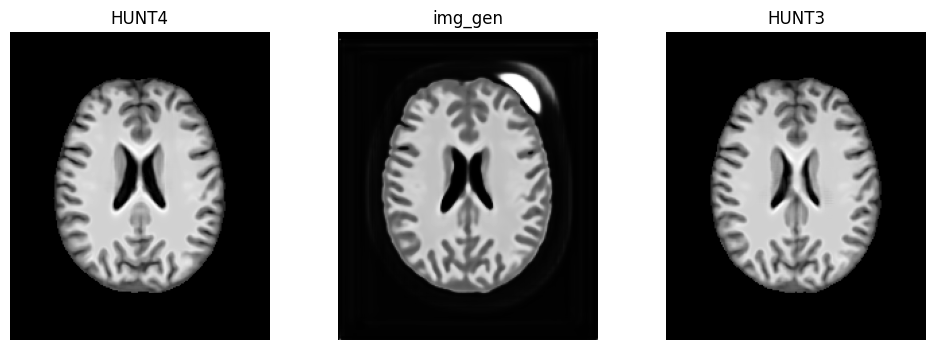

-------- Checkpoint: 2
ID: 08202


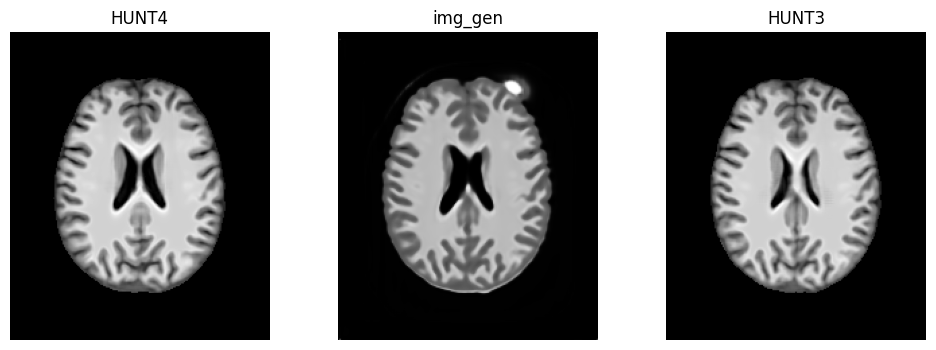

-------- Checkpoint: 3
ID: 08202


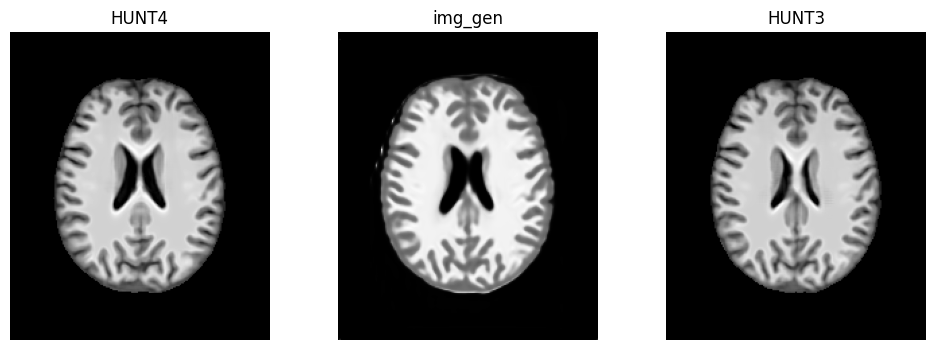

-------- Checkpoint: 4
ID: 08202


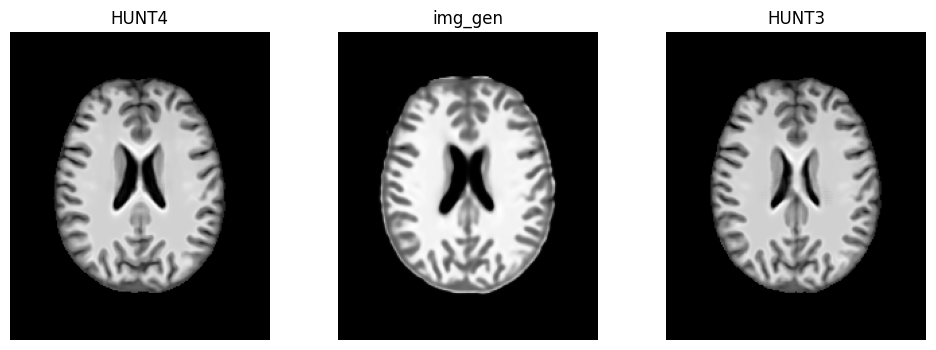

-------- Checkpoint: 5
ID: 08202


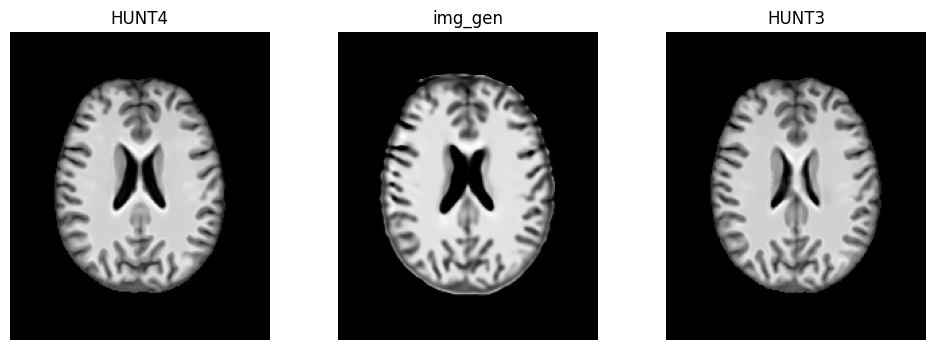

-------- Checkpoint: 6
ID: 08202


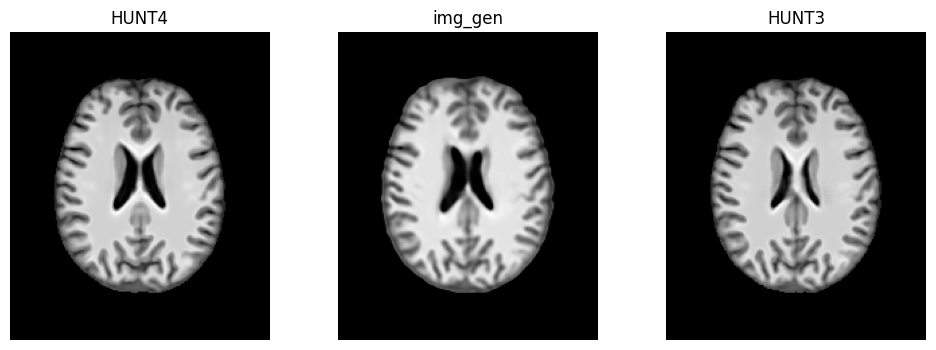

-------- Checkpoint: 7
ID: 08202


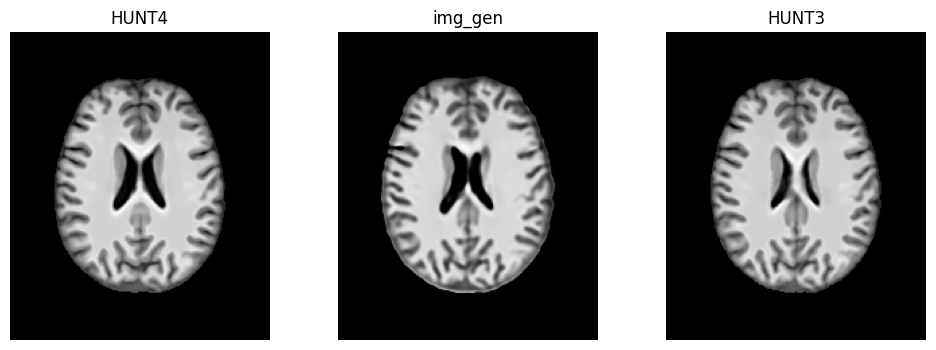

-------- Checkpoint: 8
ID: 08202


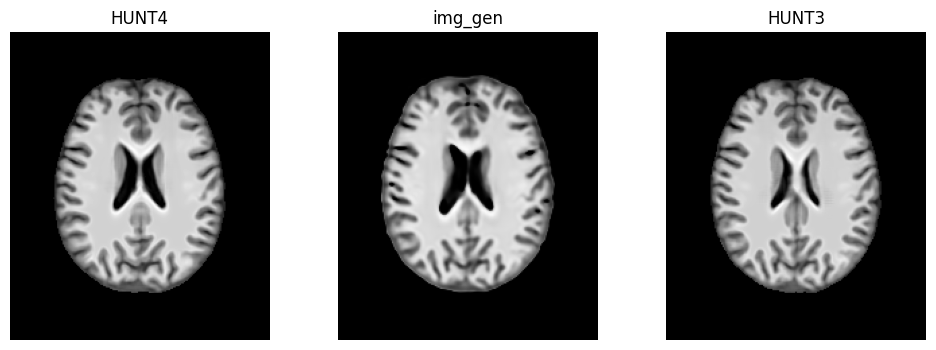

-------- Checkpoint: 9
ID: 08202


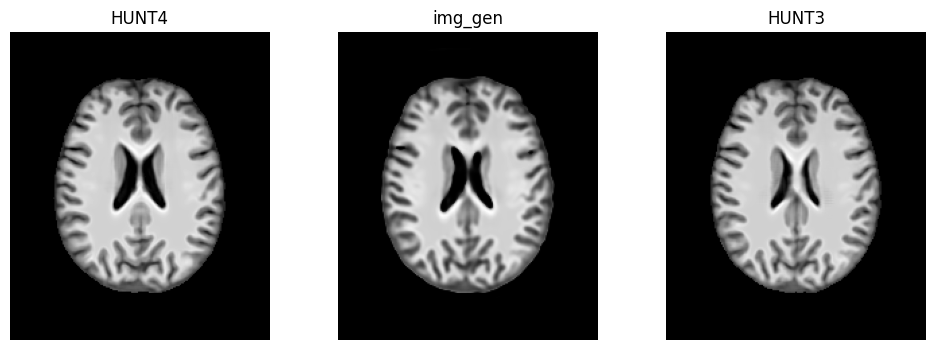

-------- Checkpoint: 10
ID: 08202


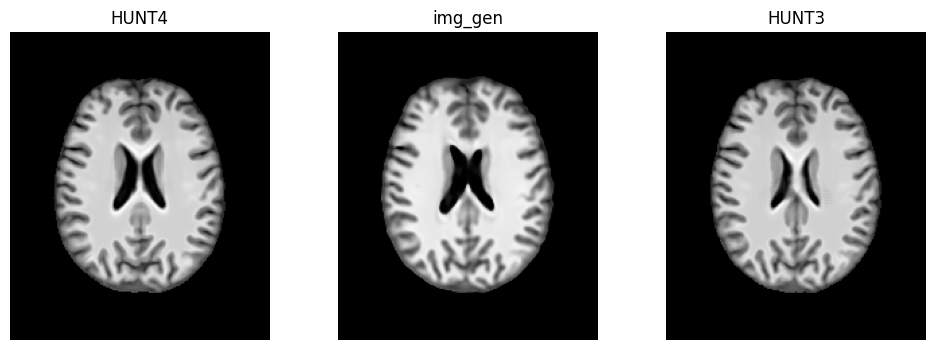

-------- Checkpoint: 11
ID: 08202


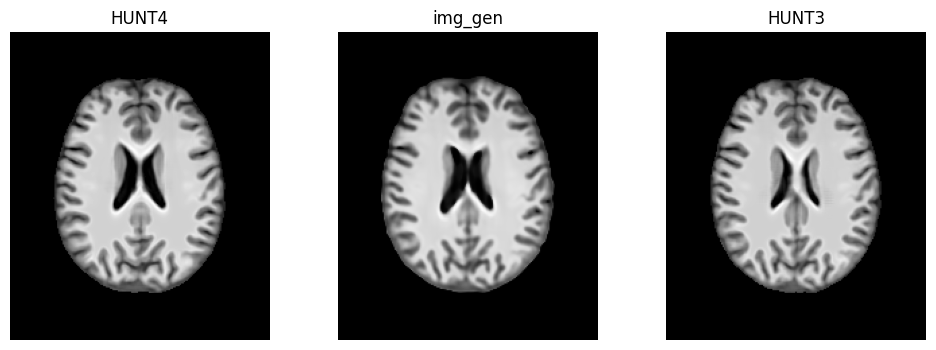

-------- Checkpoint: 12
ID: 08202


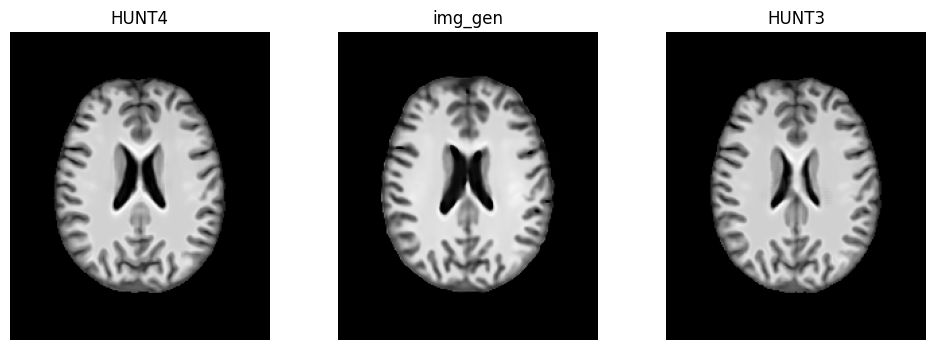

-------- Checkpoint: 13
ID: 08202


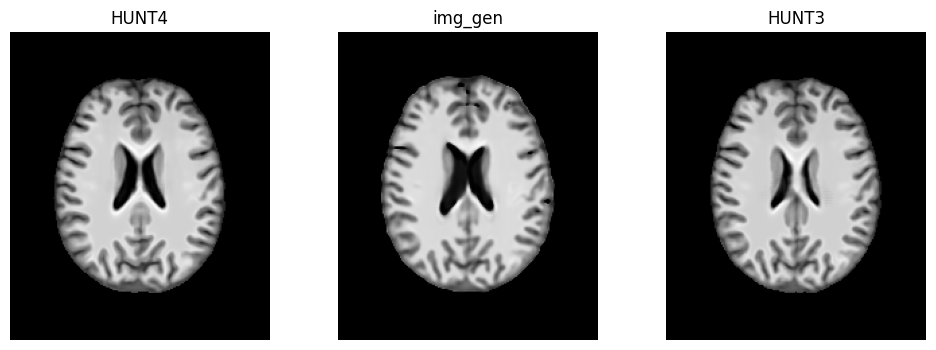

-------- Checkpoint: 14
ID: 08202


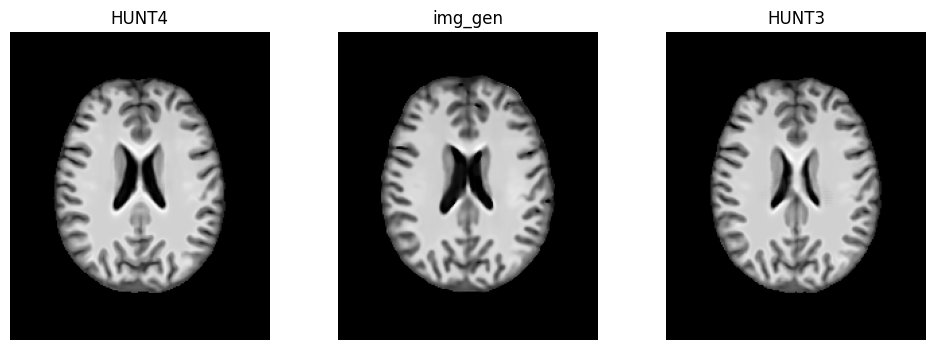

-------- Checkpoint: 15
ID: 08202


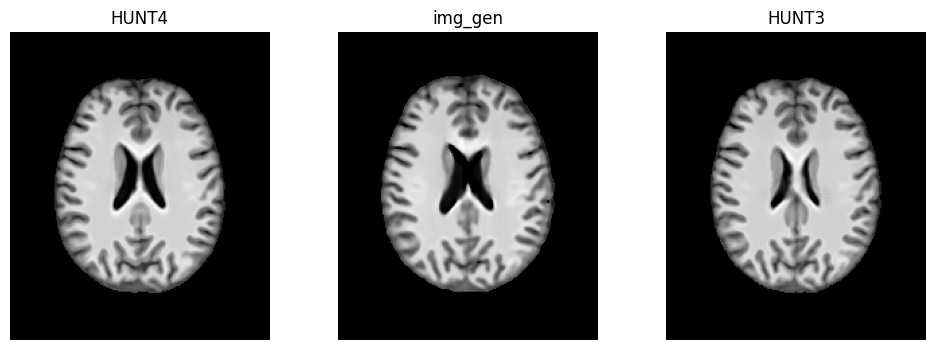

-------- Checkpoint: 16
ID: 08202


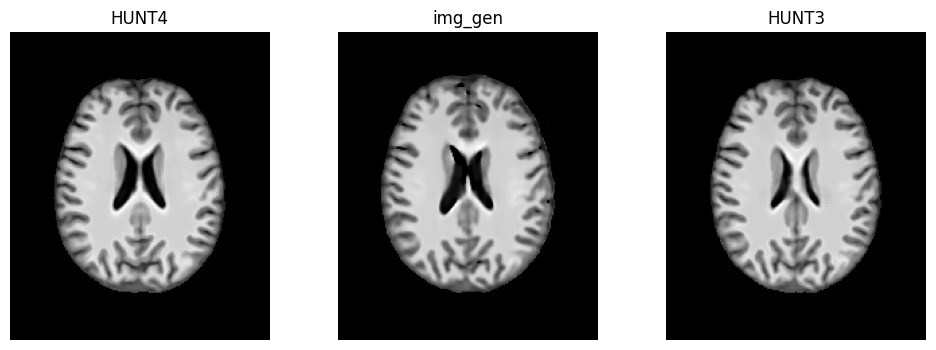

-------- Checkpoint: 17
ID: 08202


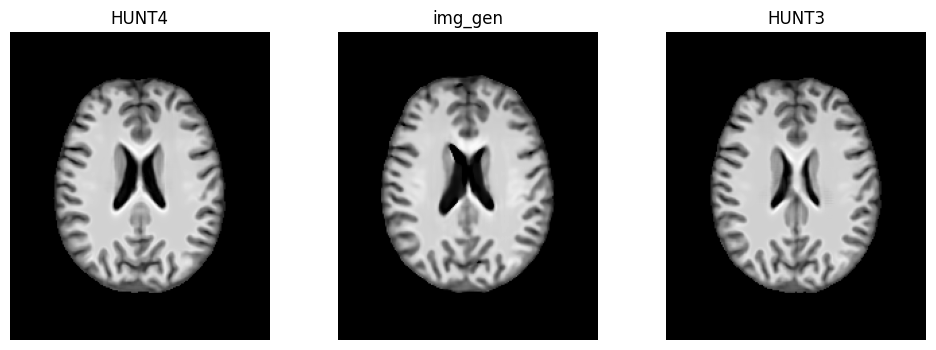

-------- Checkpoint: 18
ID: 08202


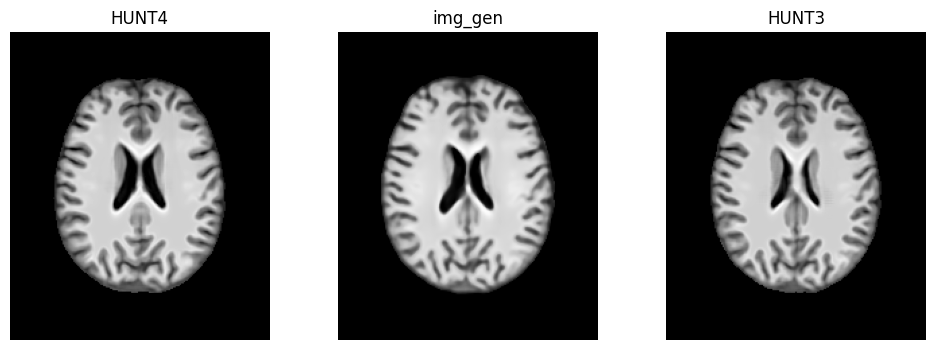

-------- Checkpoint: 19
ID: 08202


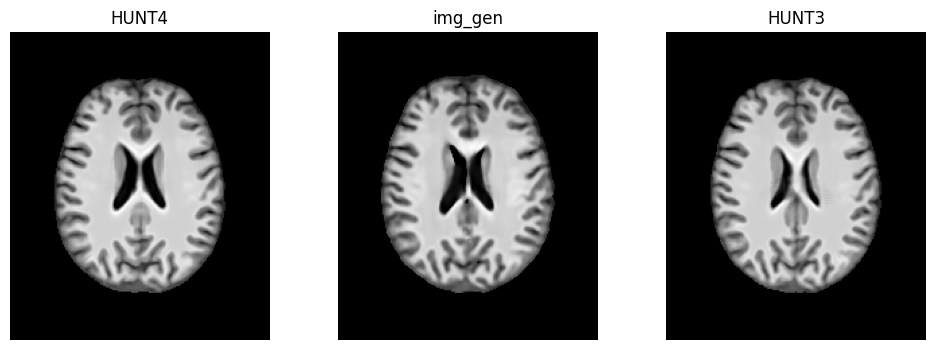

-------- Checkpoint: 20
ID: 08202


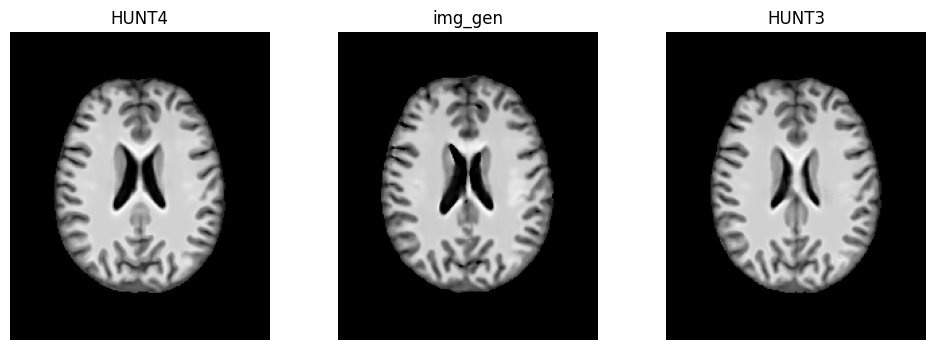

-------- Checkpoint: 21
ID: 08202


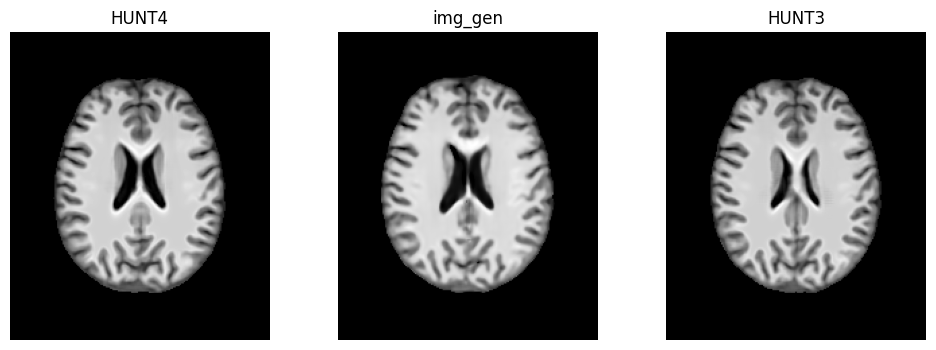

-------- Checkpoint: 22
ID: 08202


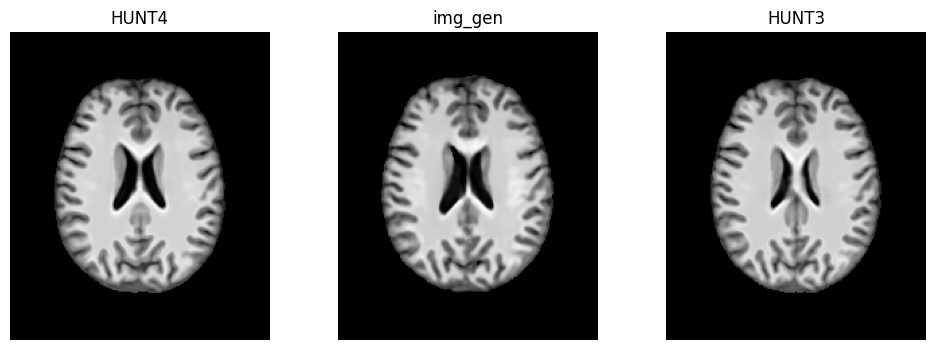

-------- Checkpoint: 23
ID: 08202


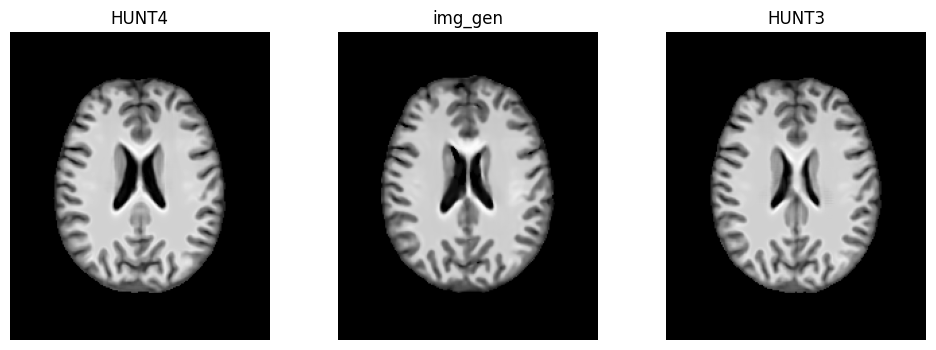

-------- Checkpoint: 24
ID: 08202


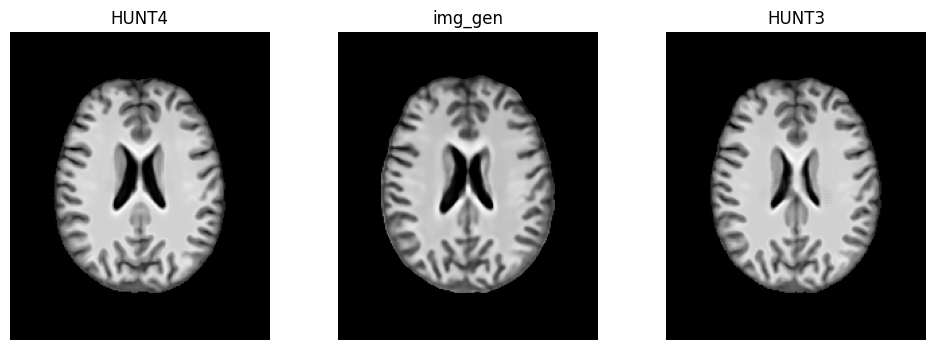

-------- Checkpoint: 25
ID: 08202


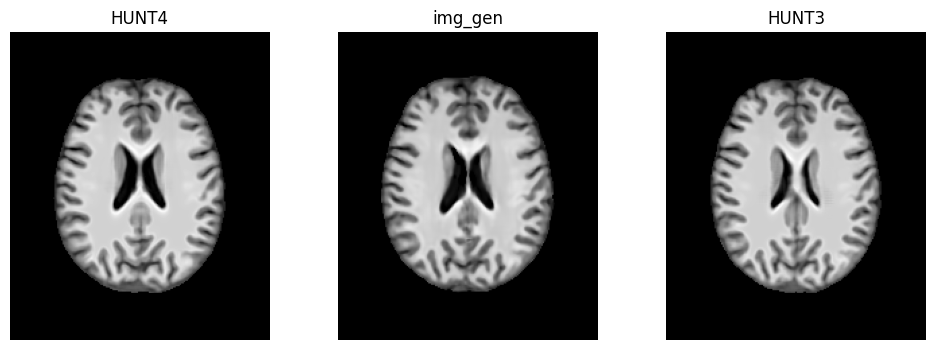

-------- Checkpoint: 26
ID: 08202


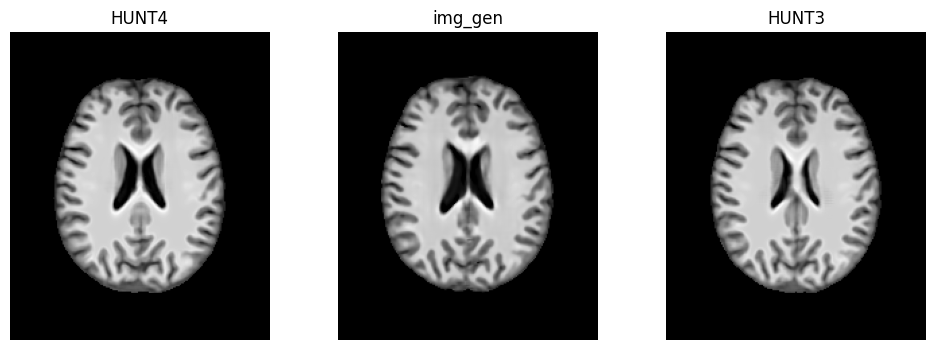

-------- Checkpoint: 27
ID: 08202


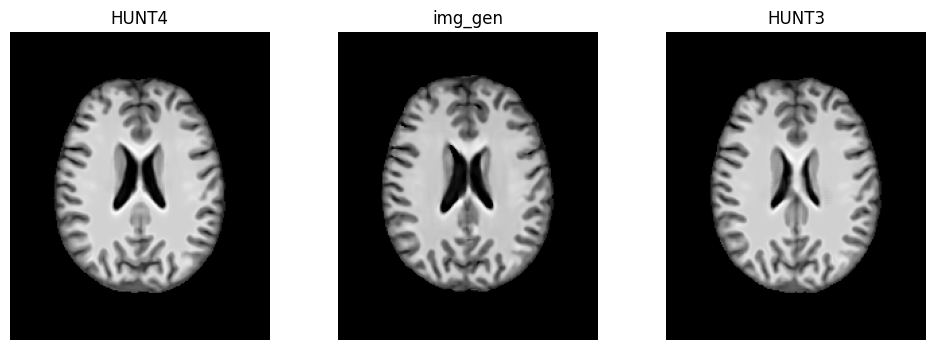

-------- Checkpoint: 28
ID: 08202


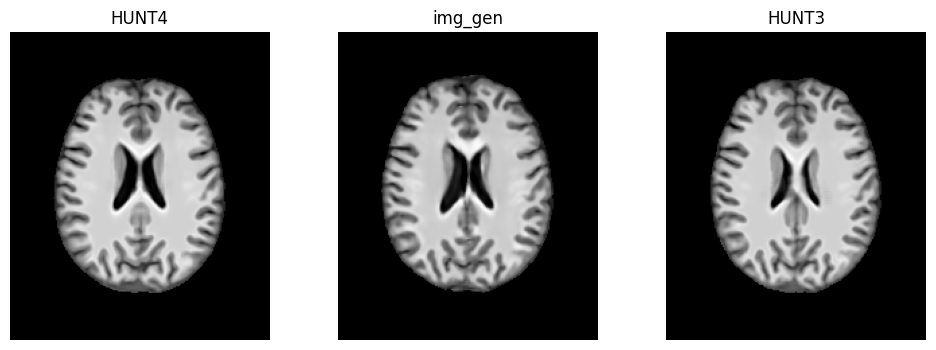

-------- Checkpoint: 29
ID: 08202


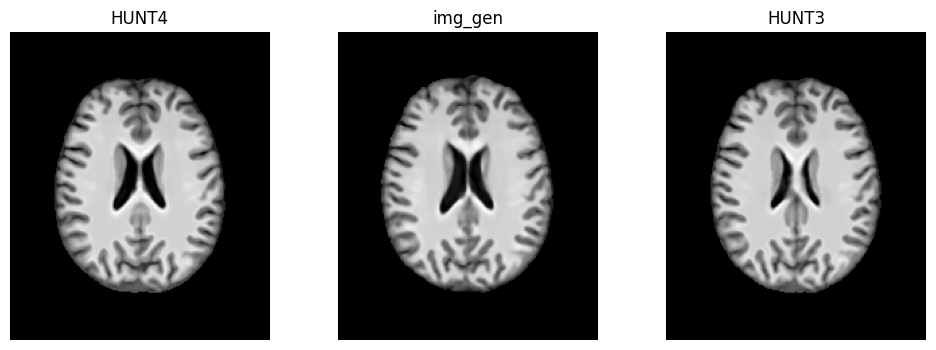

-------- Checkpoint: 30
ID: 08202


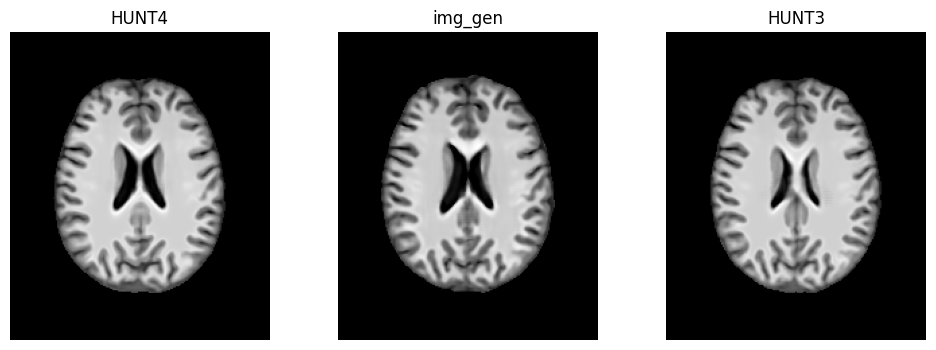

-------- Checkpoint: 31
ID: 08202


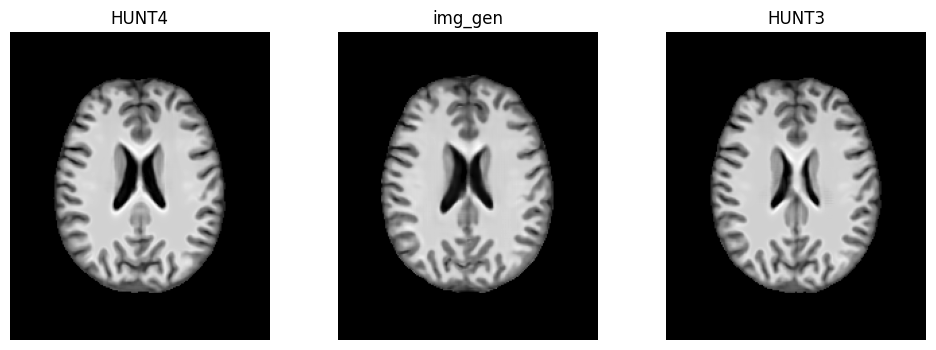

-------- Checkpoint: 32
ID: 08202


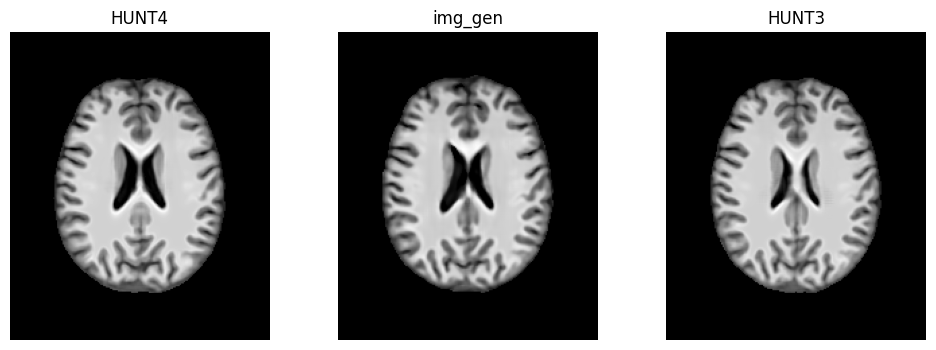

-------- Checkpoint: 33
ID: 08202


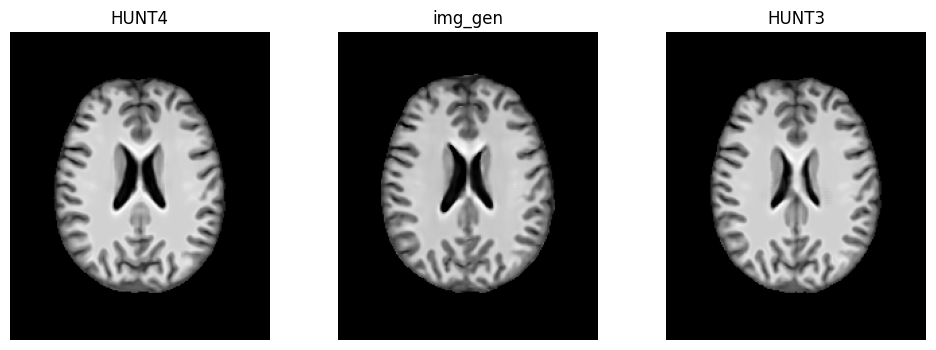

-------- Checkpoint: 34
ID: 08202


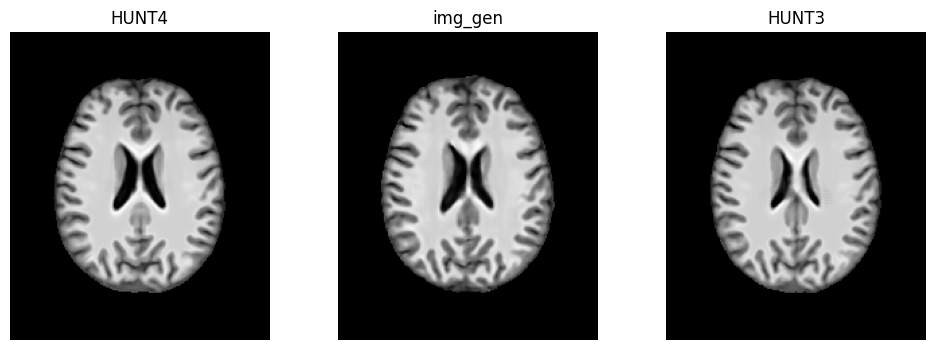

-------- Checkpoint: 35
ID: 08202


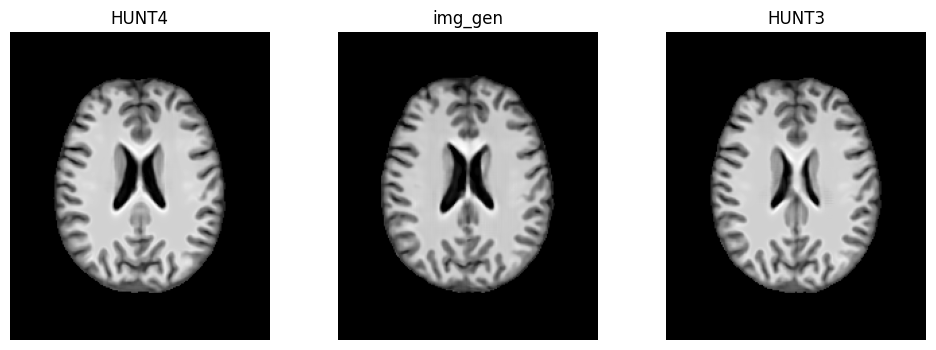

-------- Checkpoint: 36
ID: 08202


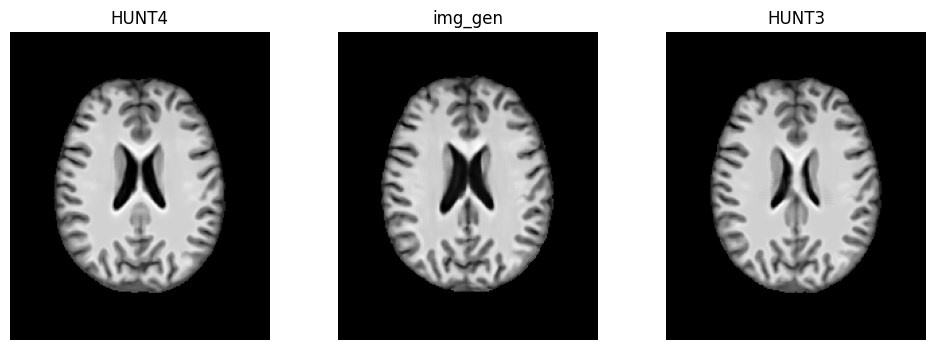

-------- Checkpoint: 37
ID: 08202


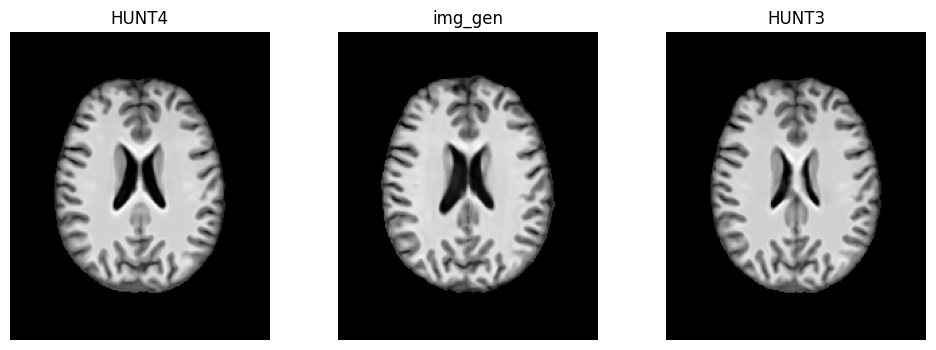

-------- Checkpoint: 38
ID: 08202


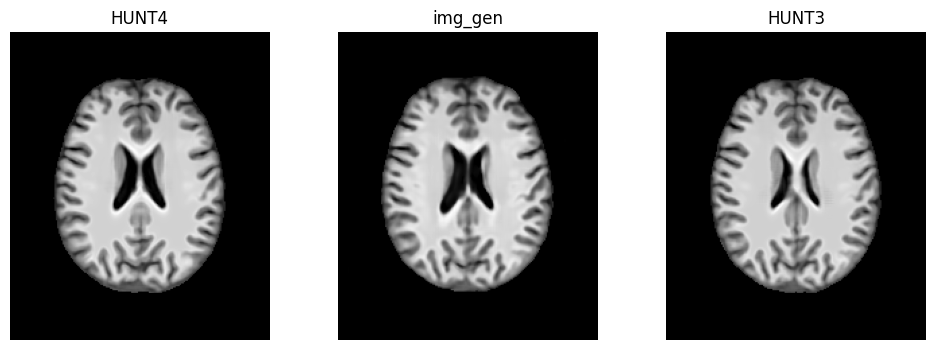

-------- Checkpoint: 39
ID: 08202


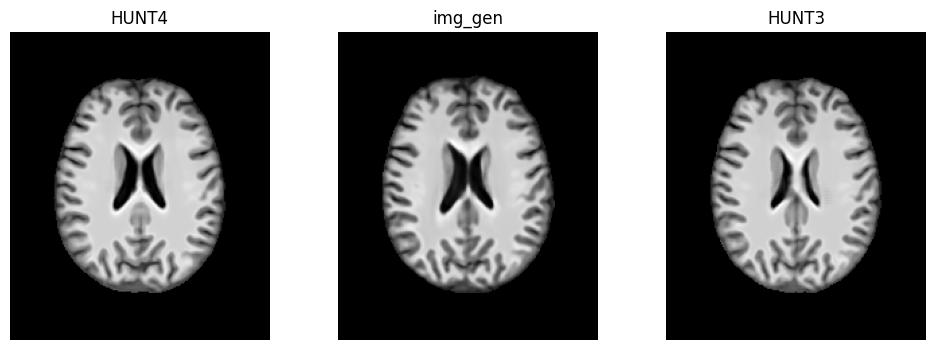

-------- Checkpoint: 40
ID: 08202


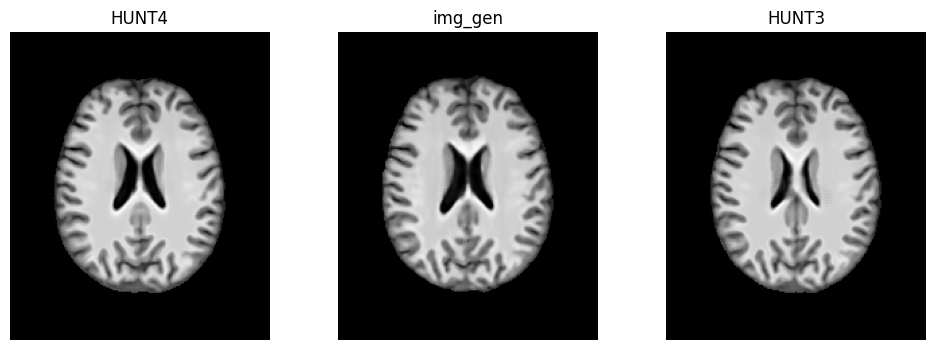

-------- Checkpoint: 41
ID: 08202


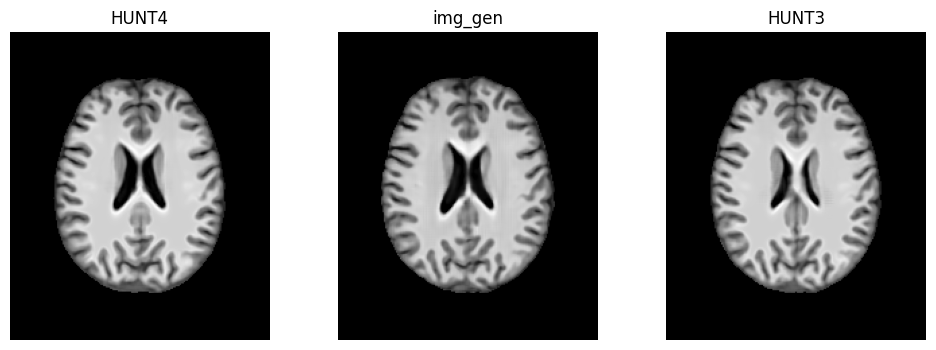

-------- Checkpoint: 42
ID: 08202


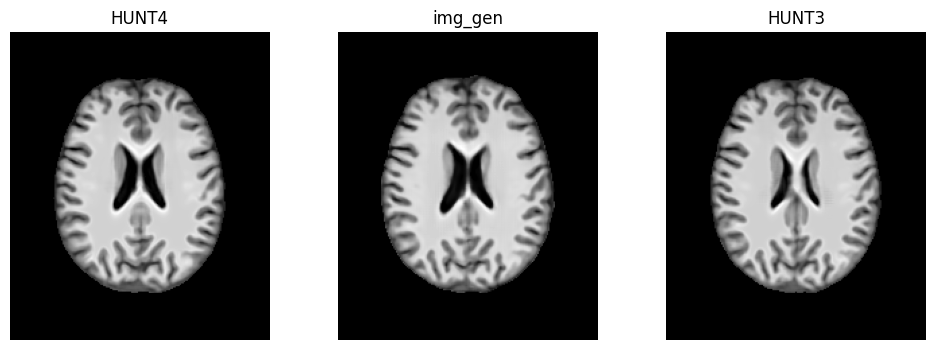

-------- Checkpoint: 43
ID: 08202


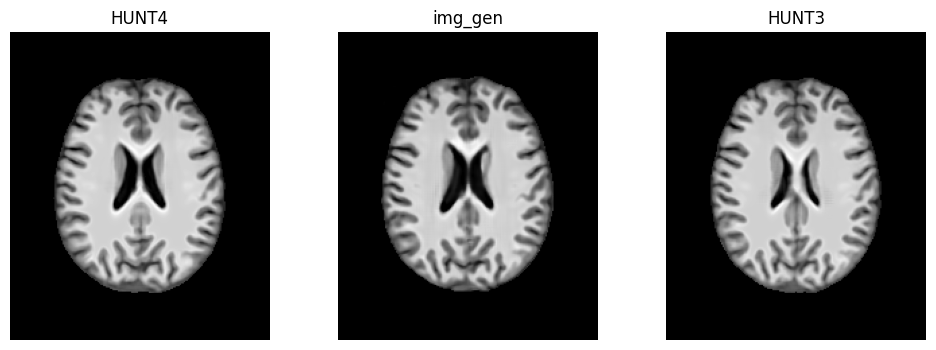

-------- Checkpoint: 44
ID: 08202


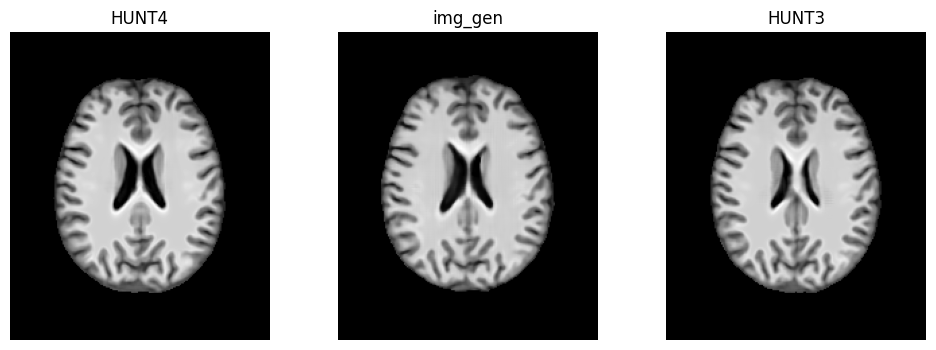

-------- Checkpoint: 45
ID: 08202


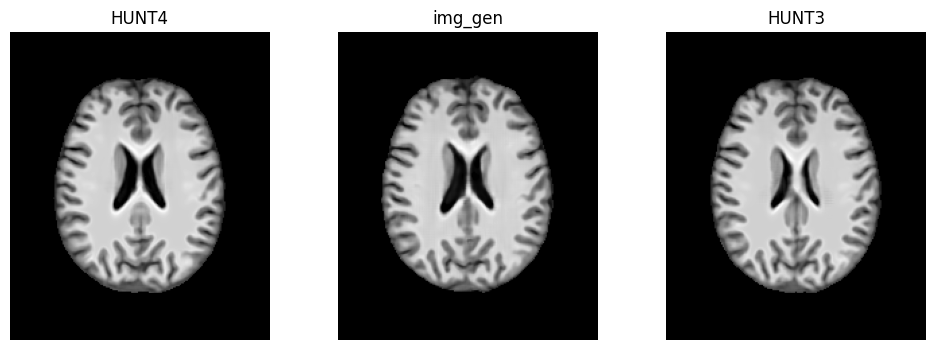

-------- Checkpoint: 46
ID: 08202


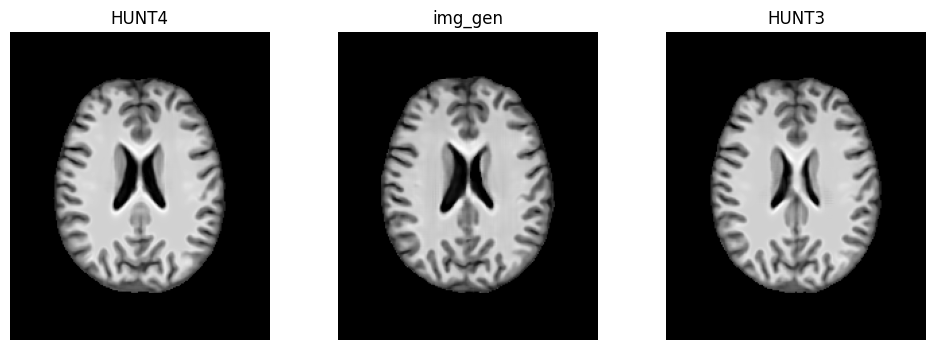

-------- Checkpoint: 47
ID: 08202


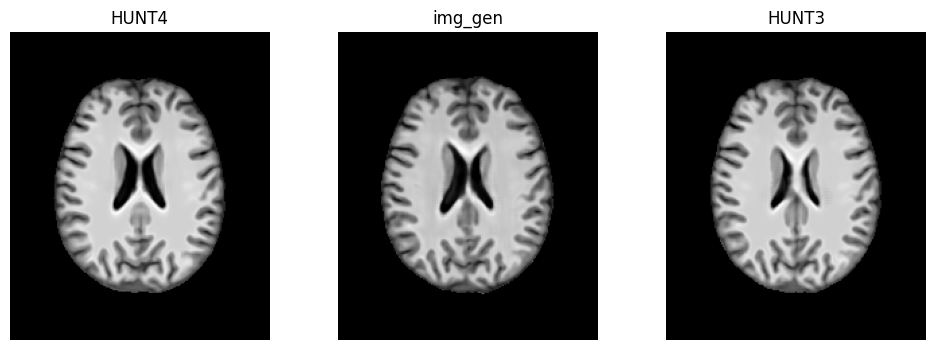

-------- Checkpoint: 48
ID: 08202


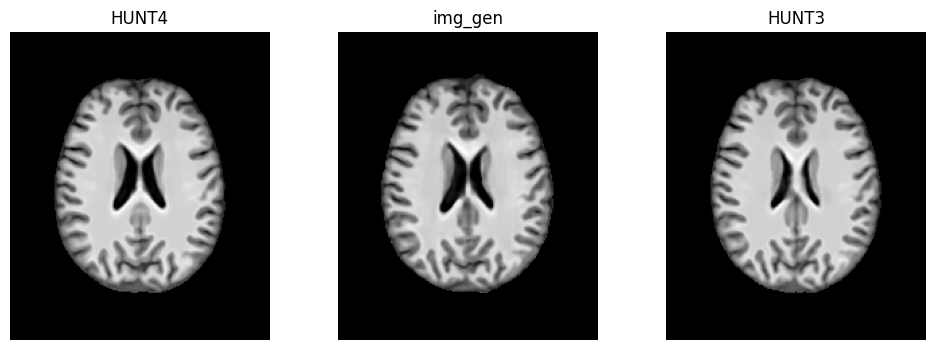

-------- Checkpoint: 49
ID: 08202


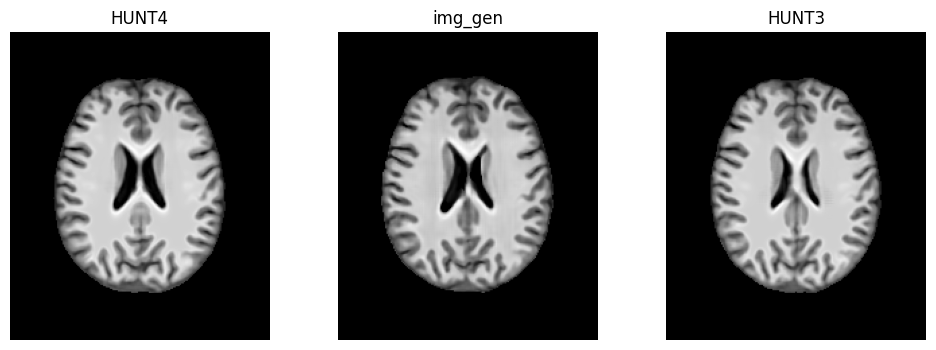

-------- Checkpoint: 50
ID: 08202


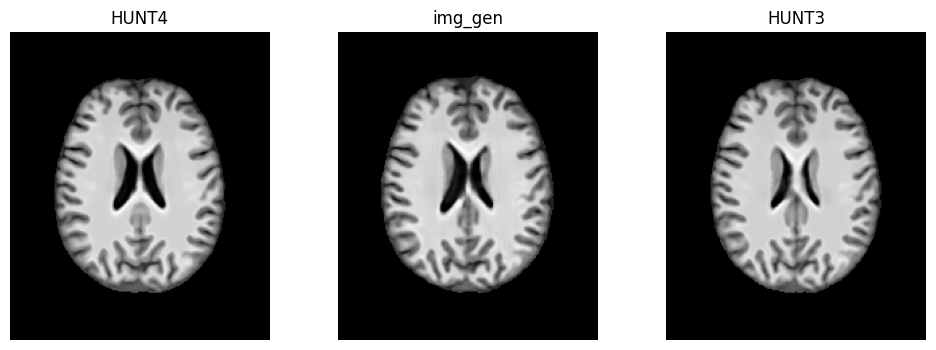

-------- Checkpoint: 51
ID: 08202


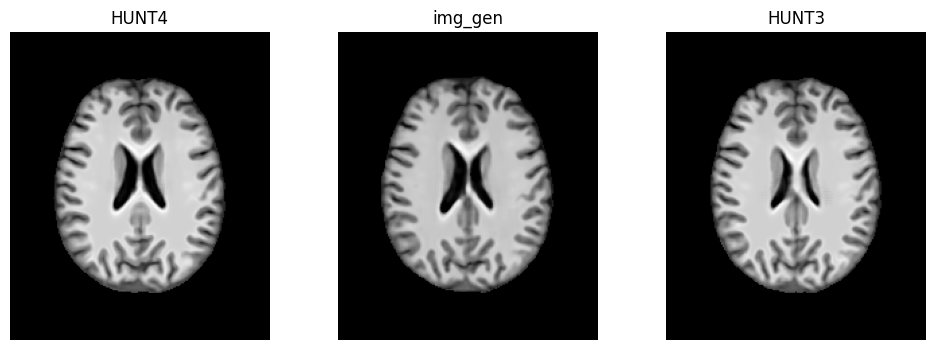

In [4]:
current_plane = 116

matching_ids = pil.get_matching_ids()
id_indexs = [366]
images_list = []
for checkpoint_index in range(1,52):
    print(f"-------- Checkpoint: {checkpoint_index}")
    checkpoint.restore(f"{checkpoint_dir}/ckpt-{checkpoint_index}")
    # checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

    for id_index in id_indexs:
        id = matching_ids[id_index]
        print(f"ID: {id}")

        img_hunt3, img_hunt4, img_gen = generate_image(id, G)
        vis.shows_3_images(img_hunt3, img_hunt4, img_gen, current_plane=current_plane)
        # vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")

        # save image
        # img_path_name = f"{current_path}/images/first_results/{id}_CHECK_{checkpoint_index}.nii.gz"
        # save_image(id, img_gen, checkpoint_index)

